# Employee Churn Prediction: step-by-step hands-on notebook
Run the cells **top to bottom** (Kernel > Restart & Run All). Each section = one step of a real analytics project.

**Goal:** predict which employees will leave (churn) and decide who HR should act on.
**Models compared:** Logistic Regression, Random Forest, XGBoost, Neural Network (deep learning).

Set `DATA_PATH` in Step 1 to wherever your CSV is.

## Step 0: Imports and settings

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, roc_curve,
                             precision_recall_curve, f1_score, precision_score, recall_score)
from xgboost import XGBClassifier

SEED = 42                      # makes results reproducible
sns.set_theme(style="whitegrid")

## Step 1: Load the data and define the target
The file has no "left the company" column, but `termination_date` is filled in only for leavers, so
`churn = 1` if a termination date exists, else `0`. This is a **binary classification** problem.

In [2]:
DATA_PATH = "employee_churn_ecommerce_retail_5000_10cols.csv"   # <-- change if needed
df = pd.read_csv(DATA_PATH)
df["churn"] = df["termination_date"].notna().astype(int)
print(df.shape)
df.head()

(5000, 11)


,employee_id,age,department,job_level,years_at_company,monthly_salary,overtime_hours_per_month,job_satisfaction,performance_rating,termination_date,churn
0,EMP-2018-AA-05583,38.0,Operations,Manager,2.42,12400.0,16.0,72.0,3.0,NaN,0
1,EMP-2018-AF-73602,36.0,Operations,Mid,1.12,6450.0,3.0,58.0,4.0,NaN,0
2,EMP-2018-AG-29732,39.0,Finance,Mid,3.67,7250.0,4.0,73.0,3.0,NaN,0
3,EMP-2018-AL-83845,21.0,Fulfillment,Mid,1.00,5100.0,35.0,19.0,2.0,2026-10-07,1
4,EMP-2018-AP-51181,36.0,Operations,Senior,3.60,9950.0,8.0,80.0,3.0,NaN,0


In [3]:
print("Churn rate:", round(df.churn.mean(), 4))       # ~12.3% -> class imbalance
df.churn.value_counts()

Churn rate: 0.1226


churn
0    4387
1     613
Name: count, dtype: int64

**Why this matters:** only ~12% leave. A model that always predicts "stays" would be ~88% accurate but useless,
so we will judge models with PR-AUC, precision and recall rather than accuracy.

## Step 2: Exploratory data analysis (EDA)
Look before you model. Check types, missing values, distributions, and how churn varies by group.

In [4]:
display(df.dtypes)
display(df.isna().sum().to_frame("missing").assign(pct=lambda d: (d.missing / len(df) * 100).round(1)))
df.describe().T

employee_id                     str
age                         float64
department                      str
job_level                       str
years_at_company            float64
monthly_salary              float64
overtime_hours_per_month    float64
job_satisfaction            float64
performance_rating          float64
termination_date                str
churn                         int64
dtype: object

,missing,pct
employee_id,0,0.0
age,90,1.8
department,121,2.4
job_level,72,1.4
years_at_company,116,2.3
monthly_salary,144,2.9
overtime_hours_per_month,174,3.5
job_satisfaction,201,4.0
performance_rating,119,2.4
termination_date,4387,87.7


,count,mean,std,min,25%,50%,75%,max
age,4910.0,34.776375,8.275734,21.00,29.00,35.00,40.0000,62.0
years_at_company,4884.0,2.863069,2.557812,0.05,1.01,2.07,3.7925,22.0
monthly_salary,4856.0,6411.717463,3117.162494,2250.00,4187.50,5500.00,7700.0000,24450.0
overtime_hours_per_month,4826.0,6.825528,5.608674,0.00,3.00,5.00,9.0000,35.0
job_satisfaction,4799.0,59.863930,16.114845,1.00,49.00,60.00,70.0000,100.0
performance_rating,4881.0,2.964761,0.642730,1.00,3.00,3.00,3.0000,5.0
churn,5000.0,0.122600,0.328010,0.00,0.00,0.00,0.0000,1.0


`termination_date` is missing for stayers by design (that is our label). All other columns have genuine ~2-4% missing values we must handle.

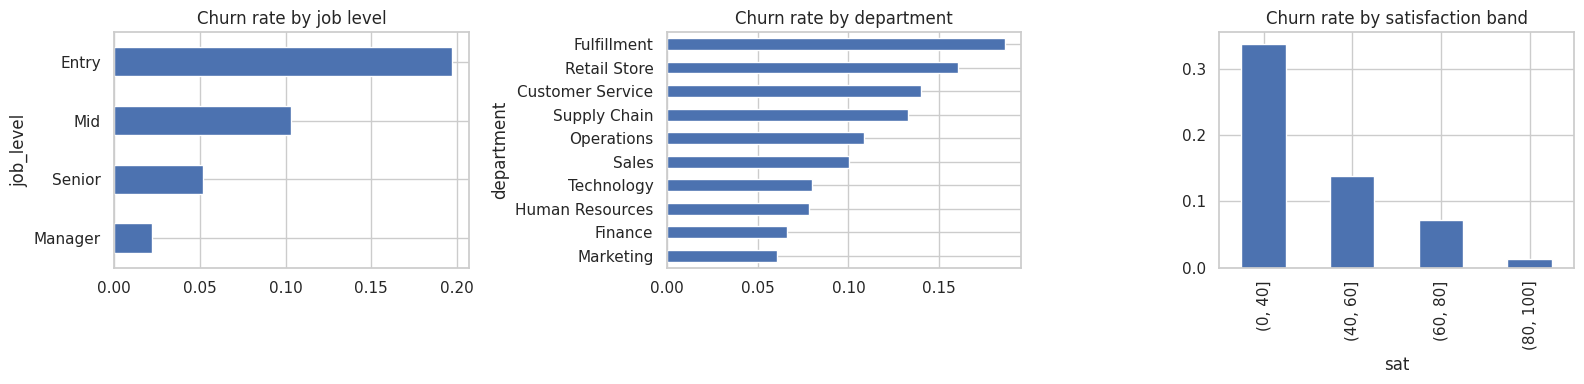

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("job_level").churn.mean().sort_values().plot.barh(ax=ax[0], title="Churn rate by job level")
df.groupby("department").churn.mean().sort_values().plot.barh(ax=ax[1], title="Churn rate by department")
df.assign(sat=pd.cut(df.job_satisfaction, [0, 40, 60, 80, 100])).groupby("sat").churn.mean().plot.bar(ax=ax[2], title="Churn rate by satisfaction band")
plt.tight_layout(); plt.show()

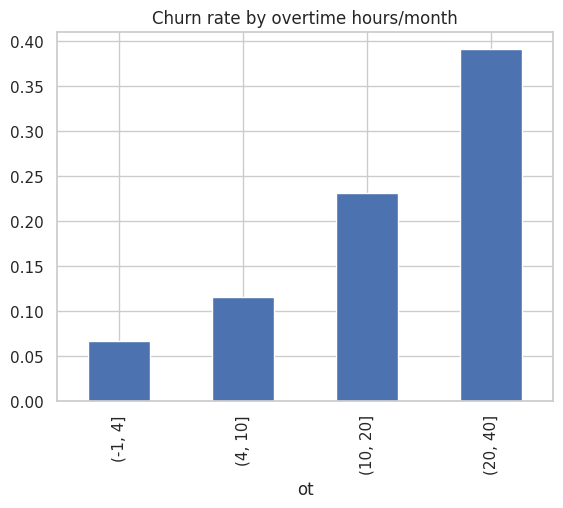

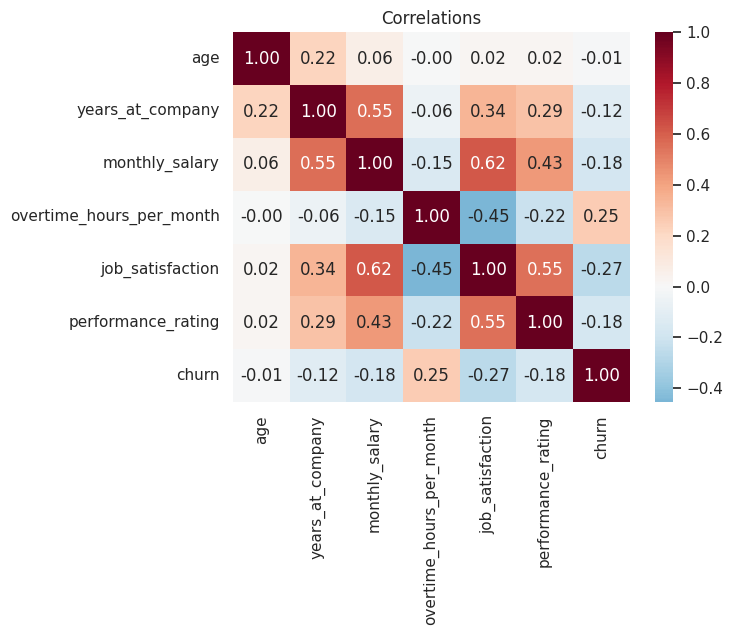

In [6]:
df.assign(ot=pd.cut(df.overtime_hours_per_month, [-1, 4, 10, 20, 40])).groupby("ot").churn.mean().plot.bar(title="Churn rate by overtime hours/month")
plt.show()
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0); plt.title("Correlations"); plt.show()

**Takeaways:** low satisfaction, high overtime, entry level and low salary go with leaving. If the models later disagree strongly with this, suspect a bug.

In [7]:
# Sanity checks: impossible values and duplicates
print("Duplicate rows (ignoring ID):", df.duplicated(subset=df.columns[1:]).sum())
print("Age range:", df.age.min(), "-", df.age.max(), "| Salary range:", df.monthly_salary.min(), "-", df.monthly_salary.max())

Duplicate rows (ignoring ID): 0
Age range: 21.0 - 62.0 | Salary range: 2250.0 - 24450.0


## Step 3: Feature selection and engineering
- **Dropped:** `termination_date` (it *is* the label; using it is **data leakage**) and `employee_id` (just an identifier).
- **New features:** log salary (salary is skewed), salary relative to peers at the same job level, and overtime × unhappiness.
- **Missing flags:** a 0/1 column per field recording "was this value missing?".

In [8]:
num = ["age", "years_at_company", "monthly_salary", "overtime_hours_per_month", "job_satisfaction", "performance_rating"]
cat = ["department", "job_level"]
X = df[num + cat].copy(); y = df["churn"]

X["log_salary"]        = np.log1p(X.monthly_salary)
X["salary_vs_level"]   = X.monthly_salary / X.groupby("job_level").monthly_salary.transform("median")
X["overtime_x_lowsat"] = X.overtime_hours_per_month * (100 - X.job_satisfaction) / 100
for c in num: X[c + "_missing"] = X[c].isna().astype(int)

num_all = num + ["log_salary", "salary_vs_level", "overtime_x_lowsat"]
miss    = [c + "_missing" for c in num]
X.head()

,age,years_at_company,monthly_salary,overtime_hours_per_month,job_satisfaction,performance_rating,department,job_level,log_salary,salary_vs_level,overtime_x_lowsat,age_missing,years_at_company_missing,monthly_salary_missing,overtime_hours_per_month_missing,job_satisfaction_missing,performance_rating_missing
0,38.0,2.42,12400.0,16.0,72.0,3.0,Operations,Manager,9.425532,0.921933,4.48,0,0,0,0,0,0
1,36.0,1.12,6450.0,3.0,58.0,4.0,Operations,Mid,8.771990,1.084034,1.26,0,0,0,0,0,0
2,39.0,3.67,7250.0,4.0,73.0,3.0,Finance,Mid,8.888895,1.218487,1.08,0,0,0,0,0,0
3,21.0,1.00,5100.0,35.0,19.0,2.0,Fulfillment,Mid,8.537192,0.857143,28.35,0,0,0,0,0,0
4,36.0,3.60,9950.0,8.0,80.0,3.0,Operations,Senior,9.205428,1.105556,1.60,0,0,0,0,0,0


## Step 4: Train / test split
Hold back 20% as an "exam" the models never see while we tune. `stratify=y` keeps the 12.3% churn rate in both halves.

In [9]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", Xtr.shape, "churn", round(ytr.mean(), 3), "| Test:", Xte.shape, "churn", round(yte.mean(), 3), "| leavers in test:", yte.sum())

Train: (4000, 17) churn 0.122 | Test: (1000, 17) churn 0.123 | leavers in test: 123


## Step 5: Cleaning pipeline (imputing, encoding, scaling)
Everything is wrapped in a **Pipeline** so that medians, scaling and categories are learned from the *training folds only*.
Cleaning the whole dataset first would leak test information and inflate scores.
- numeric: median imputation (robust to outliers), optionally standardise (needed for logistic regression and neural networks)
- categorical: most-frequent imputation, then one-hot encoding

In [10]:
def prep(scale):
    steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([
        ("n", Pipeline(steps), num_all),
        ("c", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                        ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
        ("m", "passthrough", miss)])

# Peek at what the model actually receives
demo = prep(True).fit(Xtr); print("Model input columns:", demo.transform(Xtr).shape[1])

Model input columns: 29


## Step 6: Define the four models and their search spaces
| Model | Idea | Imbalance handling |
|---|---|---|
| Logistic Regression | weighted sum squashed to a probability | `class_weight="balanced"` |
| Random Forest | many decorrelated trees vote | `balanced_subsample` |
| XGBoost | trees built sequentially, each fixing prior errors | `scale_pos_weight` |
| Neural Network (MLP) | layers of weighted sums + non-linearities | none available in sklearn (so probabilities stay calibrated) |

In [11]:
spw = (ytr == 0).sum() / (ytr == 1).sum()     # ratio of stayers to leavers

models = {
 "Logistic Regression": (Pipeline([("p", prep(True)), ("m", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        {"m__C": np.logspace(-2, 1, 20)}),
 "Random Forest": (Pipeline([("p", prep(False)), ("m", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1))]),
        {"m__max_depth": [4, 6, 8, 12, None], "m__min_samples_leaf": [5, 10, 20, 40], "m__max_features": ["sqrt", 0.5]}),
 "XGBoost": (Pipeline([("p", prep(False)), ("m", XGBClassifier(n_estimators=300, scale_pos_weight=spw, eval_metric="logloss", random_state=SEED, n_jobs=1))]),
        {"m__max_depth": [2, 3, 4], "m__learning_rate": [0.02, 0.05, 0.1], "m__subsample": [0.7, 0.9], "m__colsample_bytree": [0.7, 1.0],
         "m__min_child_weight": [1, 5, 10], "m__n_estimators": [100, 200, 400]}),
 "Neural Network (MLP)": (Pipeline([("p", prep(True)), ("m", MLPClassifier(early_stopping=True, validation_fraction=0.15, max_iter=500, random_state=SEED))]),
        {"m__hidden_layer_sizes": [(32,), (64, 32), (64, 32, 16), (128, 64)], "m__alpha": [1e-4, 1e-3, 1e-2, 1e-1], "m__learning_rate_init": [1e-3, 3e-3]}),
}
print(list(models))

['Logistic Regression', 'Random Forest', 'XGBoost', 'Neural Network (MLP)']


## Step 7: Tune with cross-validation, pick a threshold, evaluate on the test set
For each model:
1. **Randomized search + 5-fold CV** on the *training* set, optimising PR-AUC (`average_precision`), which suits imbalanced data.
2. Choose the **decision threshold** that maximises F1 on out-of-fold training predictions (so the test set stays untouched).
3. Score once on the test set.

This cell takes a few minutes.

In [12]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
res, probs, fitted = {}, {}, {}

for name, (pipe, grid) in models.items():
    n_iter = min(12, int(np.prod([len(v) for v in grid.values()])))
    rs = RandomizedSearchCV(pipe, grid, n_iter=n_iter, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=1).fit(Xtr, ytr)
    best = rs.best_estimator_

    # threshold from out-of-fold predictions on TRAIN only
    oof = cross_val_predict(best, Xtr, ytr, cv=cv, method="predict_proba")[:, 1]
    pr, rc, th = precision_recall_curve(ytr, oof)
    f1s = 2 * pr * rc / (pr + rc + 1e-9); thr = th[np.argmax(f1s[:-1])]

    p_te = best.predict_proba(Xte)[:, 1]; yhat = (p_te >= thr).astype(int)
    res[name] = dict(cv_pr_auc=rs.best_score_, roc_auc=roc_auc_score(yte, p_te), pr_auc=average_precision_score(yte, p_te),
                     precision=precision_score(yte, yhat), recall=recall_score(yte, yhat), f1=f1_score(yte, yhat),
                     brier=brier_score_loss(yte, p_te), threshold=thr)
    probs[name], fitted[name] = p_te, best
    print(f"{name:22s} done | best params: {rs.best_params_}")

Logistic Regression    done | best params: {'m__C': np.float64(0.01)}


Random Forest          done | best params: {'m__min_samples_leaf': 5, 'm__max_features': 0.5, 'm__max_depth': 4}


XGBoost                done | best params: {'m__subsample': 0.9, 'm__n_estimators': 200, 'm__min_child_weight': 5, 'm__max_depth': 2, 'm__learning_rate': 0.02, 'm__colsample_bytree': 0.7}


Neural Network (MLP)   done | best params: {'m__learning_rate_init': 0.001, 'm__hidden_layer_sizes': (128, 64), 'm__alpha': 0.1}


## Step 8: Compare the models
Metric guide: **ROC-AUC** = chance a random leaver is ranked above a random stayer (0.5 = coin flip). **PR-AUC** = quality on the leaver class (random ≈ 0.12 here).
**Precision** = of those flagged, how many really leave. **Recall** = of real leavers, how many we catch. **Brier** = probability accuracy (lower is better).

In [13]:
results = pd.DataFrame(res).T.sort_values("pr_auc", ascending=False).round(3)
results

,cv_pr_auc,roc_auc,pr_auc,precision,recall,f1,brier,threshold
Logistic Regression,0.343,0.736,0.285,0.253,0.504,0.337,0.211,0.594
XGBoost,0.332,0.719,0.281,0.236,0.488,0.318,0.212,0.584
Random Forest,0.315,0.718,0.275,0.264,0.431,0.327,0.201,0.612
Neural Network (MLP),0.338,0.722,0.270,0.239,0.593,0.341,0.102,0.164


In [14]:
# Bootstrap confidence intervals: how much would scores change with a different test sample?
rng = np.random.default_rng(SEED); yt = yte.values; ci = {}
for name in res:
    a, b = [], []
    for _ in range(500):
        i = rng.integers(0, len(yt), len(yt))
        a.append(roc_auc_score(yt[i], probs[name][i])); b.append(average_precision_score(yt[i], probs[name][i]))
    ci[name] = (np.percentile(a, [2.5, 97.5]).round(3), np.percentile(b, [2.5, 97.5]).round(3))
pd.DataFrame({"ROC-AUC 95% CI": {k: tuple(v[0]) for k, v in ci.items()}, "PR-AUC 95% CI": {k: tuple(v[1]) for k, v in ci.items()}})

,ROC-AUC 95% CI,PR-AUC 95% CI
Logistic Regression,"(0.689, 0.777)","(0.221, 0.359)"
Random Forest,"(0.671, 0.759)","(0.21, 0.353)"
XGBoost,"(0.668, 0.761)","(0.214, 0.357)"
Neural Network (MLP),"(0.678, 0.764)","(0.213, 0.355)"


**Read this carefully:** the intervals overlap heavily. No model is statistically clearly better, so we choose on interpretability, simplicity and stability.

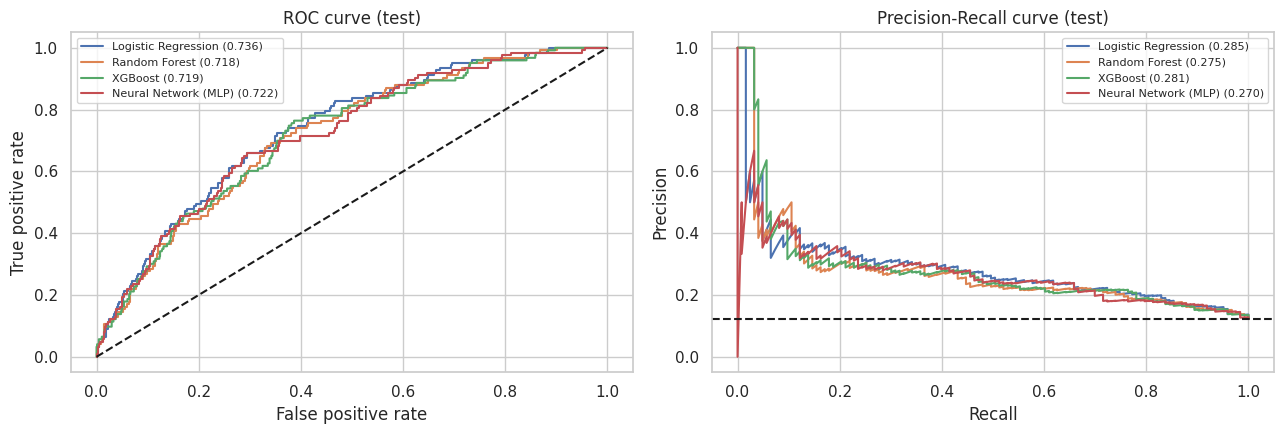

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for n, p in probs.items():
    f, t, _ = roc_curve(yte, p);            ax[0].plot(f, t, label=f"{n} ({res[n]['roc_auc']:.3f})")
    pr, rc, _ = precision_recall_curve(yte, p); ax[1].plot(rc, pr, label=f"{n} ({res[n]['pr_auc']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(title="ROC curve (test)", xlabel="False positive rate", ylabel="True positive rate")
ax[1].axhline(yte.mean(), color="k", ls="--"); ax[1].set(title="Precision-Recall curve (test)", xlabel="Recall", ylabel="Precision")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Step 9: Interpret the best model: what drives churn?
- **Permutation importance:** shuffle one feature; the bigger the score drop, the more the model relied on it.
- **Odds ratios** (logistic regression): features are standardised, so each is "per 1 standard deviation". Above 1 raises the odds of leaving, below 1 lowers them.

Best by test PR-AUC: Logistic Regression


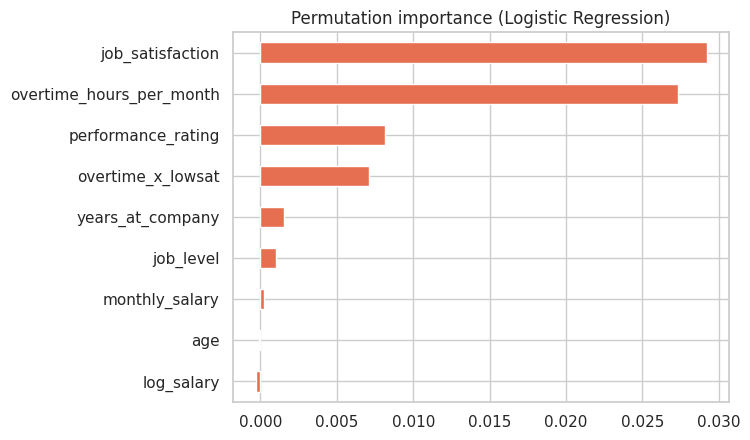

In [16]:
best_name = results.index[0]; print("Best by test PR-AUC:", best_name)
pi = permutation_importance(fitted[best_name], Xte, yte, scoring="average_precision", n_repeats=15, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values()
imp[~imp.index.str.endswith("_missing")].tail(9).plot.barh(color="#e76f51", title=f"Permutation importance ({best_name})"); plt.show()

In [17]:
lr = fitted["Logistic Regression"]
names = [n.split("__")[1] for n in lr.named_steps["p"].get_feature_names_out()]
odds = pd.Series(np.exp(lr.named_steps["m"].coef_[0]), index=names).sort_values()
odds = odds[[i for i in odds.index if not i.endswith("_missing")]]
pd.concat([odds.head(5), odds.tail(5)]).round(3).to_frame("odds ratio")

,odds ratio
job_satisfaction,0.715
log_salary,0.836
monthly_salary,0.857
department_Marketing,0.858
years_at_company,0.868
department_Customer Service,1.064
department_Fulfillment,1.077
overtime_x_lowsat,1.143
job_level_Entry,1.154
overtime_hours_per_month,1.289


## Step 10: Prescriptive layer: who should HR act on?
Prediction says *who* is at risk. Prescription asks *how many people to target* given costs.

**Editable assumptions** (replace with real HR numbers):
- replacing a leaver costs `COST_REPLACE` (1.0 = one unit)
- a retention action (stay interview, workload review) costs `COST_ACTION` per person flagged
- an action saves `SUCCESS` of the leavers it reaches

We rank by risk (not by raw probability, because class weights distort probabilities).

Break-even precision: 0.125


,share_flagged,people,leavers_caught,net_benefit
0,0.05,50,18,4.7
1,0.10,100,31,7.4
2,0.15,150,44,10.1
3,0.20,200,55,12.0
4,0.25,250,62,12.3
5,0.30,300,73,14.2
6,0.35,350,81,14.9
7,0.40,400,89,15.6
8,0.45,450,92,14.3
9,0.50,500,99,14.6


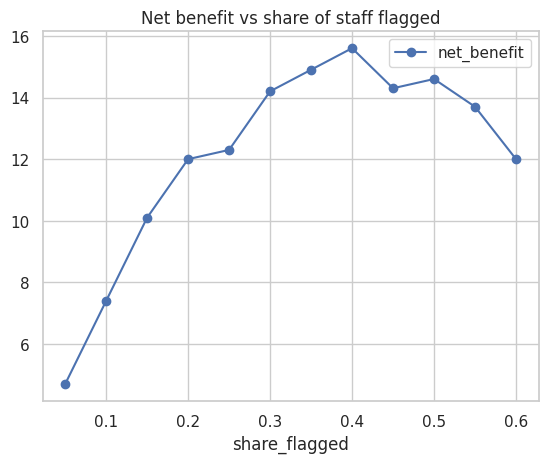

Best share to flag: 0.4


In [18]:
COST_REPLACE, COST_ACTION, SUCCESS = 1.0, 0.05, 0.40
print("Break-even precision:", COST_ACTION / (SUCCESS * COST_REPLACE))

pbest = probs[best_name]; order = np.argsort(-pbest); rows = []
for k in np.arange(0.05, 0.65, 0.05):
    n = int(len(pbest) * k); caught = int(yt[order[:n]].sum())
    rows.append(dict(share_flagged=round(k, 2), people=n, leavers_caught=caught,
                     net_benefit=round(caught * SUCCESS * COST_REPLACE - n * COST_ACTION, 2)))
curve = pd.DataFrame(rows); display(curve)
curve.plot(x="share_flagged", y="net_benefit", marker="o", title="Net benefit vs share of staff flagged"); plt.show()
print("Best share to flag:", curve.loc[curve.net_benefit.idxmax(), "share_flagged"])

In [19]:
# Risk tiers: do they separate real churn rates?
rank = pd.Series(pbest).rank(ascending=False, pct=True).values
tiers = pd.cut(rank, [0, .10, .30, 1], labels=["High (top 10%)", "Medium (next 20%)", "Low (rest)"], include_lowest=True)
print(pd.DataFrame({"tier": tiers, "churned": yt}).groupby("tier", observed=True).churned.agg(people="size", actual_churn="mean").round(3))
top20 = yt[order[:int(len(yt) * .2)]].sum() / yt.sum()
print(f"Top 20% highest-risk staff contain {top20:.0%} of all leavers (random targeting = 20%)")

                   people  actual_churn
tier                                   
High (top 10%)        100         0.310
Medium (next 20%)     200         0.210
Low (rest)            700         0.071
Top 20% highest-risk staff contain 45% of all leavers (random targeting = 20%)


## Step 11: Conclusions
1. All four models land at ROC-AUC ≈ 0.72-0.74; the differences are inside the confidence intervals.
2. **Recommended:** regularised **Logistic Regression**. It scored highest, is explainable to HR, and trains in seconds. Keep **XGBoost** as the challenger if you add richer features.
3. The **neural network** is not worth the complexity for 5,000 rows × 10 columns.
4. Main drivers: **job satisfaction**, **overtime**, then performance rating; entry-level staff are most at risk.
5. Limitations: association is not causation (pilot interventions with a control group), only ~123 leavers in the test set, termination dates are mostly future-dated, no leaving reason, and age/department should be checked for fairness.

### Exercises
- Remove the engineered features (Step 3) and see how scores change.
- Replace median imputation with `strategy="constant"` and compare.
- Change `test_size` or `SEED` and see how much metrics wobble.
- Add `SVC(probability=True)` or `LightGBM` to the `models` dictionary.
- Set `COST_ACTION = 0.15` and watch net benefit go negative.